In [1]:
import sys
import sklearn
import numpy as np
import pandas as pd
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from datetime import datetime

from numpy import mean
from numpy import std
from numpy import absolute
from pandas import read_csv
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler


We importen de verschillende tabbelen die in de DWH aanwezig zijn

In [2]:
from sqlalchemy import create_engine
import pandas as pd


from urllib.parse import quote_plus

driver = '{ODBC Driver 17 for SQL Server}'
params = quote_plus(f"DRIVER={driver};SERVER=Pip-Boy\\MSSQLSERVER01;DATABASE=WifiDWH;Trusted_Connection=yes;")

engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

We cleanen elke tabel op, en daarna mergen we ze

Ik kies uit DimDate om de volgende kolommen te bewaren:
  - DateKey, zodat mergen met de facttable mogelijk is
  - DayofYear, zodat we weten hoe ver in het jaar dat we zijn
  - Weekday_sin en Weekday_cos, om de effecten van spijbelen op maandag/vrijdag te zien
  - Month_sin en Month_cos
  


In [3]:
def prepare_df_date():
  df_date = pd.read_sql_query('SELECT * FROM DimDate', engine)
  df_date['Weekday'] = (df_date['Weekday']+5)%7

  df_date['Weekday_sin'] = np.sin(2 * np.pi *df_date['Weekday']/7)
  df_date['Weekday_cos'] = np.cos(2 * np.pi *df_date['Weekday']/7)


  df_date['Month_sin'] = np.sin(2 * np.pi *df_date['Month']/7)
  df_date['Month_cos'] = np.cos(2 * np.pi *df_date['Month']/7)


  df_date = df_date[['DateKey', 'DayOfYear', 'Weekday_sin', 'Weekday_cos', 'Month_sin', 'Month_cos']]

  return df_date
df_date = prepare_df_date()
df_date.head()

,DateKey,DayOfYear,Weekday_sin,Weekday_cos,Month_sin,Month_cos
0,20250101,1,0.974928,-0.222521,0.781831,0.62349
1,20250102,2,0.433884,-0.900969,0.781831,0.62349
2,20250103,3,-0.433884,-0.900969,0.781831,0.62349
3,20250104,4,-0.974928,-0.222521,0.781831,0.62349
4,20250105,5,-0.781831,0.623490,0.781831,0.62349


Voor DimClass maak ik mijn keuze door te kijken naar de lessen-subgroepen.csv. Aangezien dat de enigste informatie dat we krijgen de ClassCredits zijn, haal ik dit eruit.
  

In [4]:
def prepare_df_class():
  df_class = pd.read_sql_query('SELECT * FROM DimClass', engine)
  df_class = df_class[['ClassKey', 'ClassCredits']]
  return df_class

df_class= prepare_df_class()
df_class.head()

,ClassKey,ClassCredits
0,1,3
1,2,3
2,3,3
3,4,3
4,5,3


Ik hou de volgende kolommen bij van DimActivity:
  - ActivityKey: nodig om te mergen met de facttable
  - CanonicalActivity: Wordt gegeven aan ons.
  - IsCourse
  - IsPractical
  - IsExam
  - IsDigitalPossible

De booleans die ik niet heb meegenomen zijn allemaal dezelfde waarde in de facttable.

Je merkt ook op dat ik duplicates op canonicalactivity eruit heb gehaald. Dit is omdat je soms meerdere versie van dezelfde soort examen hebt, met het enigste verschil dat het in de sourcecolom als WorkFormExam in plaats van WorkFormEvaluation wordt aangeduid

In [5]:
def prepare_df_activity():
  df_activity = pd.read_sql_query('SELECT * FROM DimActivity', engine)
  df_activity = df_activity[["ActivityKey", "CanonicalActivity", "IsCourse", 'IsPractical', 'IsExam','IsDigitalPossible']]
  df_activity = df_activity.drop_duplicates(['CanonicalActivity'])
  return df_activity
df_activity = prepare_df_activity()
df_activity.head()

,ActivityKey,CanonicalActivity,IsCourse,IsPractical,IsExam,IsDigitalPossible
0,1,Unknown,False,False,False,False
1,2,Activerend hoorcollege,True,False,False,False
2,3,Begeleiding,True,False,False,False
3,4,Excursie,True,False,False,False
4,5,Leerpad vast,True,False,False,False


Ik neem uit DimTime de TimeKey mee en FullTime zodat ik de tijd kan bepalen.

In [6]:
def prepare_df_tijd():
  df_tijd = pd.read_sql_query('SELECT * FROM DimTime', engine)
  df_tijd['FullTime'] =  pd.to_datetime(df_tijd['FullTime'], format='%H:%M:%S')
  df_tijd = df_tijd[["TimeKey", "FullTime"]]
  return df_tijd

df_tijd = prepare_df_tijd()
df_tijd.head()

,TimeKey,FullTime
0,0,1900-01-01 00:00:00
1,1,1900-01-01 00:00:01
2,2,1900-01-01 00:00:02
3,3,1900-01-01 00:00:03
4,4,1900-01-01 00:00:04


Ik neem uit DimSubgroup alles mee

In [7]:
def prepare_df_subgroup():
  df_subgroup = pd.read_sql_query('SELECT * FROM DimSubgroup', engine)
  #df_subgroup = df_subgroup.drop(['ProgramName'], axis=1)
  return df_subgroup

df_subgroup = prepare_df_subgroup()
df_subgroup.head()


,SubgroupKey,SubgroupCode,ProgramName
0,5717669,PBA-SO/LOBR/2A,PBA-SO
1,5717692,PBA-SO/LOBR/2A,PBA-SO
2,5717823,PBA-SO/LOBR/2A,PBA-SO
3,5717824,PBA-SO/LOBR/2A,PBA-SO
4,5717825,PBA-SO/LOBR/2A,PBA-SO


Voor de kolommen van dimRoom neem ik de gegeven kolommen uit lessen-subgroepen.csv. Ik maak ook een extra kolom Ruimte aan, wat de ratio tussen Area en Capacity is.

In [8]:
def prepare_df_room():
  df_room = pd.read_sql_query('SELECT * FROM DimRoom', engine)
  df_room['Ruimte'] = df_room['Area']/df_room['Capacity']
  df_room = df_room[["RoomKey", "RoomFloor", "Category", "Capacity", "Area", 'Ruimte']]
  return df_room

df_room = prepare_df_room()
df_room.head()


,RoomKey,RoomFloor,Category,Capacity,Area,Ruimte
0,433,0,consultatie,4,12.00,3.000000
1,437,0,consultatie,8,12.00,1.500000
2,438,0,consultatie,4,12.00,3.000000
3,514,2,laptoplokaal,24,56.02,2.334167
4,515,4,PC-klas,54,106.13,1.965370


Ik maak in factlecture de aanwezigheidsgraad aan. 
Er zijn veel kolommen met een aanwezigheidsgraad van Nan, dit komt omdat er nog geen usercount werd genomen van die moment. Ik drop die rijen
Ik drop ook de kolomn met lectureId, aangezien dat we de leerkracht niet krijgen voor een klas/

In [9]:
def prepare_df_fact():
  df_fact = pd.read_sql_query('SELECT * FROM FactLecture', engine)
  df_fact['Aanwezigheidsgraad'] = df_fact["UserCount"] / df_fact["TotalStudents"]
  df_fact = df_fact[df_fact['Aanwezigheidsgraad'].notna()]
  df_fact = df_fact.drop(columns=["LectureID"])
  return df_fact

df_fact = prepare_df_fact()
df_fact.info()
df_fact.head()


<class 'pandas.DataFrame'>
Index: 6977 entries, 0 to 18493
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   DateKey             6977 non-null   int64  
 1   FromTimeKey         6977 non-null   int64  
 2   UntilTimeKey        6977 non-null   int64  
 3   ClassKey            6977 non-null   int64  
 4   SubgroupKey         6977 non-null   int64  
 5   RoomKey             6977 non-null   int64  
 6   ActivityKey         6977 non-null   int64  
 7   UserCount           6977 non-null   float64
 8   TotalStudents       6977 non-null   int64  
 9   Aanwezigheidsgraad  6977 non-null   float64
dtypes: float64(2), int64(8)
memory usage: 599.6 KB


,DateKey,FromTimeKey,UntilTimeKey,ClassKey,SubgroupKey,RoomKey,ActivityKey,UserCount,TotalStudents,Aanwezigheidsgraad
0,20251103,154500,174500,4790,5732011,2301,2,5.0,20,0.250000
1,20251103,154500,174500,4790,5900314,2301,2,7.0,17,0.411765
2,20251103,154500,174500,4790,5900370,2301,2,4.0,21,0.190476
3,20251103,154500,174500,4790,5974366,2301,2,2.0,21,0.095238
4,20251103,154500,174500,4790,6048579,2301,2,1.0,21,0.047619


Ik weet dat studenten bij heel slecht of heel zonnig weer niet naar de les gaan, dus maak ik een extra tabel over het weer aan. 

Uit deze tabel haal ik de timestamp (datum), de precip_quantity, de sun_int_avg en de temp_avg


In [10]:
def prepare_df_weer():
  df_weer = pd.read_csv('aws_1day.csv')
  df_weer = df_weer[df_weer['the_geom'] == 'POINT (50.98 3.816)'] #dichtsbijzijnde bij Gent
  df_weer['timestamp'] = df_weer['timestamp'].str[:4]+df_weer['timestamp'].str[5:7] + df_weer['timestamp'].str[8:10]
  df_weer['timestamp'] = pd.to_numeric(df_weer['timestamp'])

  df_weer['is_regen'] = df_weer['precip_quantity'] != 0
  df_weer = df_weer[['timestamp', 'sun_int_avg', 'sun_duration', 'temp_avg', 'is_regen']]
  #Slecht weer = veel regen (precip_quantity) == geen studenten
  #Goed weer = veel zon/hoge temperaturen == cafeweer, geen studenten
  return df_weer

df_weer = prepare_df_weer()


Alles tabellen worden bij de facttable gemergd, en de keys worden gedropt.

In [19]:

df_all = pd.merge(df_fact, df_class)
df_all = df_all.merge(df_activity)
df_all = df_all.merge(df_date)
df_all = df_all.merge(df_subgroup)
df_all = df_all.merge(df_room)
df_all = df_all.merge(df_weer, left_on='DateKey', right_on='timestamp')
df_all = df_all.merge(df_tijd, left_on="FromTimeKey", right_on="TimeKey") #Wordt aangegeven met _x
df_all = df_all.merge(df_tijd, left_on="UntilTimeKey", right_on="TimeKey") #Wordt aangegeven met _y
df_all = df_all.rename(columns={"FullTime_x": "FromFullTime", "FullTime_y": "UntillFullTime"})
df_all = df_all.drop(columns=['DateKey', 'FromTimeKey', 'UntilTimeKey', 'ClassKey', 'SubgroupKey', 'RoomKey', 'ActivityKey', 'TimeKey_x', 'TimeKey_y', 'timestamp'])
df_all.head()



,UserCount,TotalStudents,Aanwezigheidsgraad,ClassCredits,CanonicalActivity,IsCourse,IsPractical,IsExam,IsDigitalPossible,DayOfYear,...,Category,Capacity,Area,Ruimte,sun_int_avg,sun_duration,temp_avg,is_regen,FromFullTime,UntillFullTime
0,5.0,20,0.250000,3,Activerend hoorcollege,True,False,False,False,307,...,laptoplokaal,90,142.48,1.583111,19.12,49.42,10.78,True,1900-01-01 15:45:00,1900-01-01 17:45:00
1,7.0,17,0.411765,3,Activerend hoorcollege,True,False,False,False,307,...,laptoplokaal,90,142.48,1.583111,19.12,49.42,10.78,True,1900-01-01 15:45:00,1900-01-01 17:45:00
2,4.0,21,0.190476,3,Activerend hoorcollege,True,False,False,False,307,...,laptoplokaal,90,142.48,1.583111,19.12,49.42,10.78,True,1900-01-01 15:45:00,1900-01-01 17:45:00
3,2.0,21,0.095238,3,Activerend hoorcollege,True,False,False,False,307,...,laptoplokaal,90,142.48,1.583111,19.12,49.42,10.78,True,1900-01-01 15:45:00,1900-01-01 17:45:00
4,1.0,21,0.047619,3,Activerend hoorcollege,True,False,False,False,307,...,laptoplokaal,90,142.48,1.583111,19.12,49.42,10.78,True,1900-01-01 15:45:00,1900-01-01 17:45:00


Ik maak nog een kolom ClassTime aan, hoe lang dat een klas duurt. 

Ik transformeer ook de tijdkolomen en day_of_year naar cyclische eenheden.

Het reindexeren van de kolomen is niet noodzakelijk, maar dat maakt het voor mij gemakkelijker om later terug te vinden wat de namen van de kolommen zijn, zodat ik ze kan gebruiken in opdracht.py

In [20]:
def prepare_all(all):
  all['ClassTime'] = (all['UntillFullTime'] - all['FromFullTime']).dt.total_seconds() /60

  all['FromMinutes'] = all['FromFullTime'].dt.hour * 60 + all['FromFullTime'].dt.minute  
  all['UntillMinutes'] = all['UntillFullTime'].dt.hour * 60 + all['UntillFullTime'].dt.minute  

  all['FromHour_sin'] = np.sin(2 * np.pi *all['FromMinutes']/1440)
  all['FromHour_cos'] = np.cos(2 * np.pi * all['FromMinutes']/1440) 
  all['UntillHour_sin'] = np.sin(2 * np.pi * all['UntillMinutes']/1440)
  all['UntillHour_cos'] = np.cos(2*np.pi*all['UntillMinutes']/1440)   

  all['ClassTime'] = all['ClassTime'].astype('int64')


  all['DayOfYear_sin'] = np.sin(2 * np.pi * all['DayOfYear'] / 365)
  all['DayOfYear_cos'] = np.cos(2 * np.pi * all['DayOfYear'] / 365)
  all = all.drop(['UserCount', 'TotalStudents', 'FromFullTime', 'UntillFullTime'], axis=1)
  all = all.reindex(['DayOfYear_sin', 'DayOfYear_cos','Weekday_sin', 'Weekday_cos', 'Month_sin', 'Month_cos', 'FromHour_sin', 'FromHour_cos', 'UntillHour_sin', 'UntillHour_cos','ClassTime' , 'CanonicalActivity', 'SubgroupCode', "IsCourse", 'IsPractical', 'IsExam', 'IsDigitalPossible',
                              'ProgramName', 'RoomFloor', 'Category', 'Capacity', 'Area', 'Ruimte', 'ClassCredits', 'is_regen', 'sun_int_avg', 'sun_duration', 'temp_avg', 'Aanwezigheidsgraad'], axis=1)
  return all
df_final = prepare_all(df_all)
df_final.info()


<class 'pandas.DataFrame'>
RangeIndex: 6977 entries, 0 to 6976
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   DayOfYear_sin       6977 non-null   float64
 1   DayOfYear_cos       6977 non-null   float64
 2   Weekday_sin         6977 non-null   float64
 3   Weekday_cos         6977 non-null   float64
 4   Month_sin           6977 non-null   float64
 5   Month_cos           6977 non-null   float64
 6   FromHour_sin        6977 non-null   float64
 7   FromHour_cos        6977 non-null   float64
 8   UntillHour_sin      6977 non-null   float64
 9   UntillHour_cos      6977 non-null   float64
 10  ClassTime           6977 non-null   int64  
 11  CanonicalActivity   6977 non-null   str    
 12  SubgroupCode        6977 non-null   str    
 13  IsCourse            6977 non-null   bool   
 14  IsPractical         6977 non-null   bool   
 15  IsExam              6977 non-null   bool   
 16  IsDigitalPossible

De aanwezigheidsgraad is zwaar geskewed. 1/4de van de klassen hebben een aanwezigheidsgraad van 0. 

Er zijn meerdere mogelijkheden om dit aan te pakken. Eén manier, wat buiten de scope van de opdracht viel, zou zijn om eerst een classifier model te maken die kijkt op iemand/niemand aanwezig, en als er iemand aanwezig was, dan de regressie model aanroepen die ging kijken hoeveel mensen er aanwezigen gingen zijn.

Ik heb voor een iets gemakkelijker methode gekozen. 1/4 is heel veel, meer dan dat eigenlijk realistisch is. Wat er waarschijnlijk zou zijn, is dat er mensen aanwezig waren, maar dat er niemand in de les een connectie heeft gemaakt met de WiFi (Internet die plat lag, gebrek aan toestel, gewoonweg niet verbonden,...)

Ik drop dus alle 0 waarden. 

In [21]:
df_final['Aanwezigheidsgraad'].value_counts()


df_final= df_final[df_final['Aanwezigheidsgraad'] !=0.0]
#df_final = df_final.drop_duplicates()

df_final.info()

<class 'pandas.DataFrame'>
Index: 5277 entries, 0 to 6976
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   DayOfYear_sin       5277 non-null   float64
 1   DayOfYear_cos       5277 non-null   float64
 2   Weekday_sin         5277 non-null   float64
 3   Weekday_cos         5277 non-null   float64
 4   Month_sin           5277 non-null   float64
 5   Month_cos           5277 non-null   float64
 6   FromHour_sin        5277 non-null   float64
 7   FromHour_cos        5277 non-null   float64
 8   UntillHour_sin      5277 non-null   float64
 9   UntillHour_cos      5277 non-null   float64
 10  ClassTime           5277 non-null   int64  
 11  CanonicalActivity   5277 non-null   str    
 12  SubgroupCode        5277 non-null   str    
 13  IsCourse            5277 non-null   bool   
 14  IsPractical         5277 non-null   bool   
 15  IsExam              5277 non-null   bool   
 16  IsDigitalPossible   52

We bekijken de finale data visueel. Je hebt een paar peaks, zoals ClassTime of temp_avg, maar niets dat verdacht eruit ziet.

Het enige stukje dat er een beetje raar kan zijn, is de outlier bij Capacity en Area. Vermoedlijk is dit een auditorium, maar ik heb het nagekeken voor de zekerheid.

Category
auditorium    289
Name: count, dtype: int64

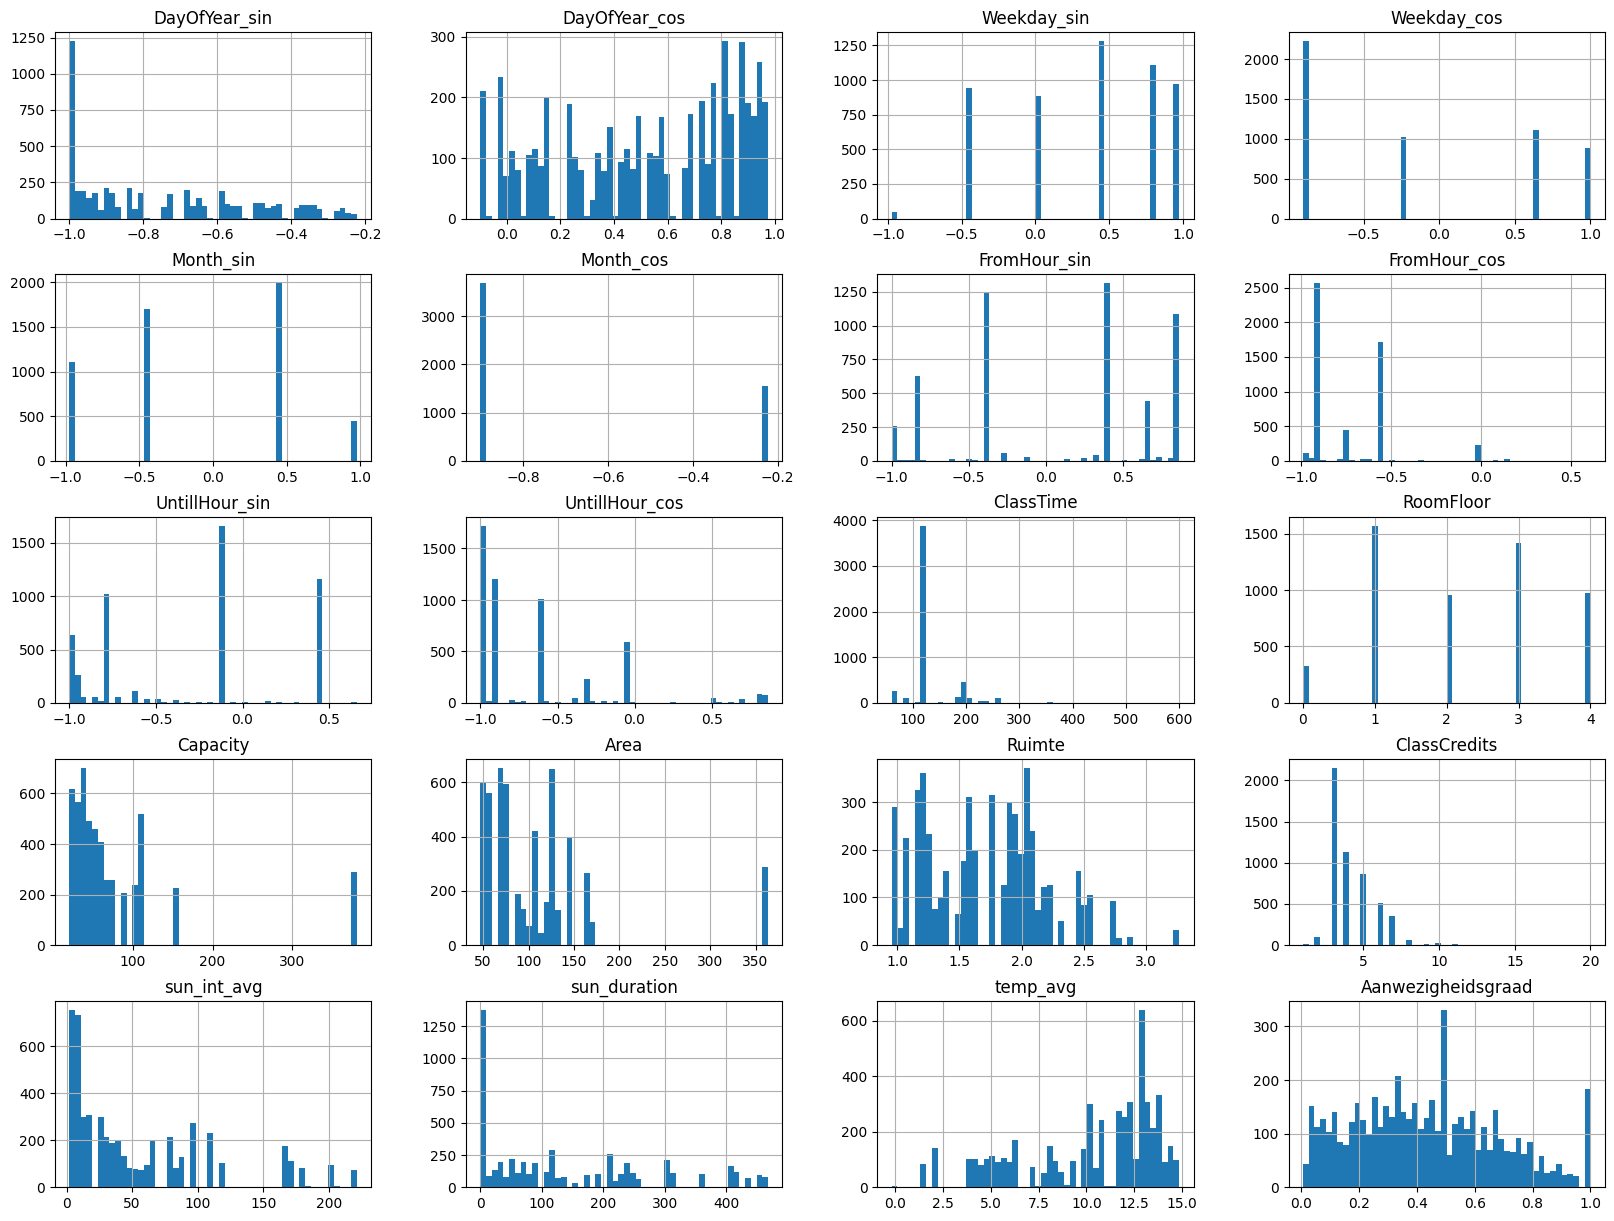

In [14]:
df_final.hist(bins=50, figsize=(20,15))


#1 outlier van lokaal ivm capacity en Area, vermoedlijk een auditorium, maar eens nakijken voor de zekerheid
df_final[df_final['Capacity'] >=300]['Category'].value_counts()
#Inderdaad: enkel auditoriums, dus dit is in orde

In [15]:
#split dataset

from sklearn.model_selection import train_test_split

X = df_final.drop(['Aanwezigheidsgraad'], axis=1)
y = df_final['Aanwezigheidsgraad']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42)

We hebben 4 soorten kolommen. Kolommen met een hoge kardinaliteit, kolommen met een lage kardinaliteit, kolommen die booleans zijn, en kolommen die numerical zijn

Hoge en lage cardinaliteit werd bepaald met behulp van value_counts

In [16]:

high_card_cols = ['SubgroupCode', 'ProgramName']
low_card_cols = ['Category','CanonicalActivity']

binary_cols = [c for c in X.columns if X[c].dtype == 'bool']
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns



In [17]:

from sklearn.preprocessing import StandardScaler

from sklearn.preprocessing import TargetEncoder
preprocessing = ColumnTransformer(transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('high', TargetEncoder(target_type='continuous', random_state=42), high_card_cols),
        ('low', OneHotEncoder(handle_unknown='ignore'), low_card_cols + binary_cols)
    ], remainder='passthrough'
)



Nu dat we preprocessing hebben, kunnen we de correlatie bepalen tussen aanwezigheidsgraad en de andere kolommen.

De meeste correlaties hier zijn niet verassend. Een sterke postieve correlatie bij labo's, die meestal verplicht zijn, maar een sterke negatieve correlatie bij hoorcollege's. Het engiste verrassende voor mij is hoe laag is_regen stond. Ik dacht dat meer studenten regenweer als excuus gingen gebruiken.

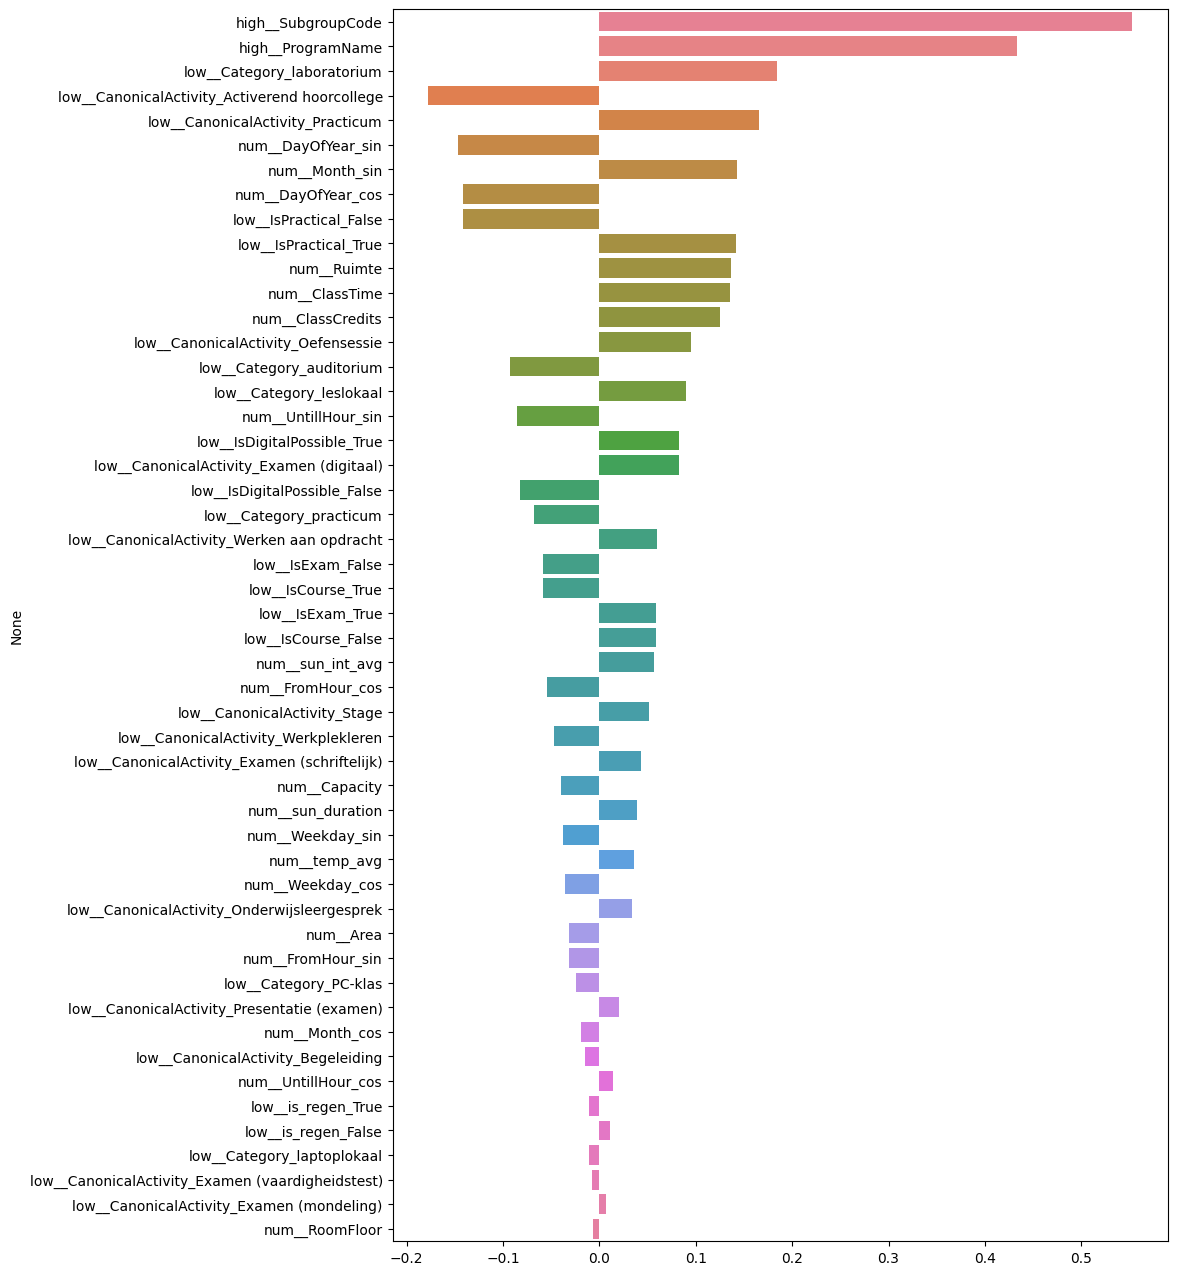

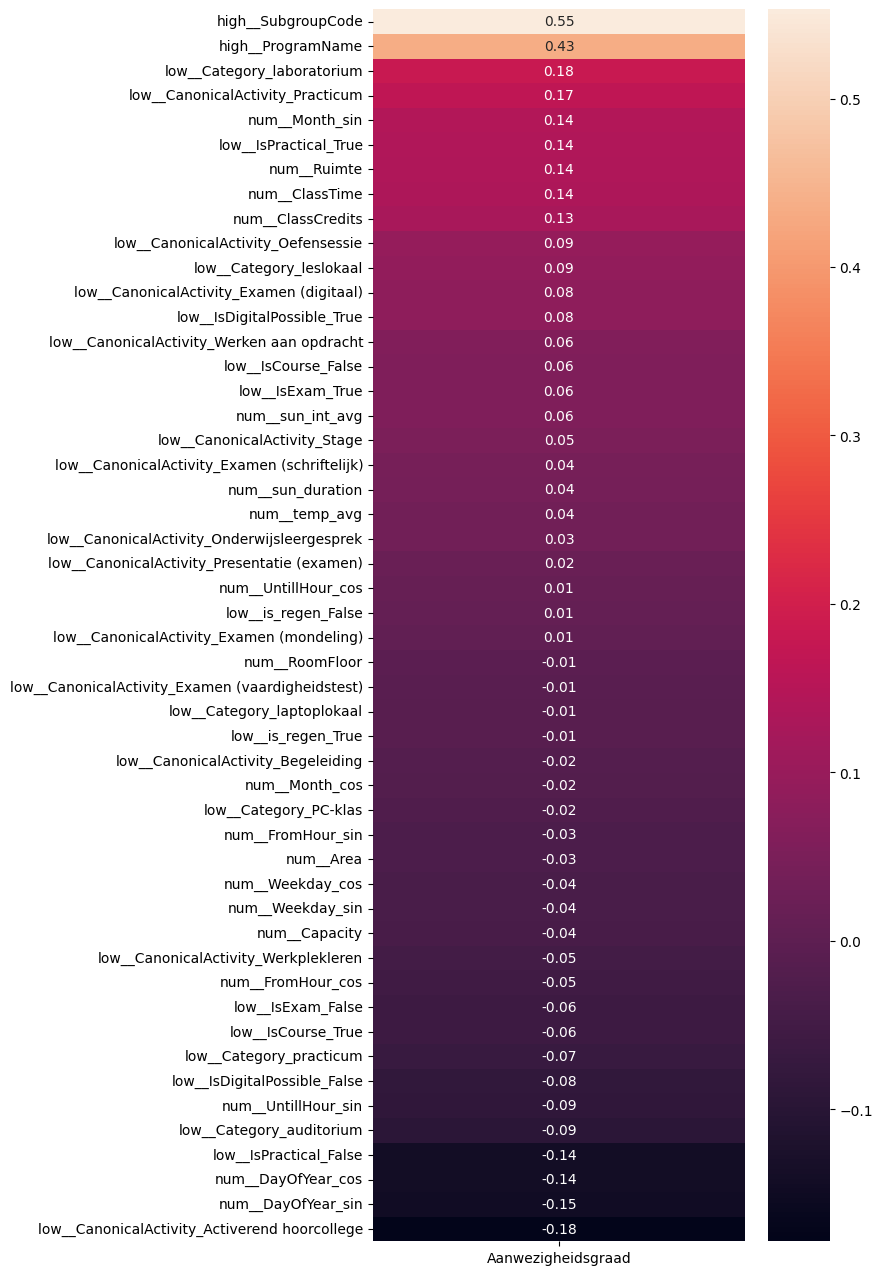

In [18]:
import seaborn as sns
X_prep = preprocessing.fit_transform(X, y)
feature_names = preprocessing.get_feature_names_out()

df_encoded = pd.DataFrame(X_prep, columns=feature_names)

df_encoded['Aanwezigheidsgraad'] = y.values

corr_matrix = df_encoded.corr()


target_corr = corr_matrix['Aanwezigheidsgraad'].drop('Aanwezigheidsgraad')
target_corr_sorted = target_corr.sort_values(ascending=False)
#Absolute sortering: duidelijker wat meeste invloed heeft
target_corr_sorted_abs = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

plt.figure(figsize=(10, 16))
sns.barplot(
    x=target_corr_sorted_abs.values, 
    y=target_corr_sorted_abs.index, 
    hue=target_corr_sorted_abs.index,
)

plt.show()

plt.figure(figsize=(6, 16))
sns.heatmap(target_corr_sorted.to_frame(), annot=True, fmt=".2f")

plt.show()


Ik analyseer meerdere modellen op basis van mean absolute error. Ik kijk ook naar de learning curve, zodat ik kan zien in hoeverre de data overfit wordt.

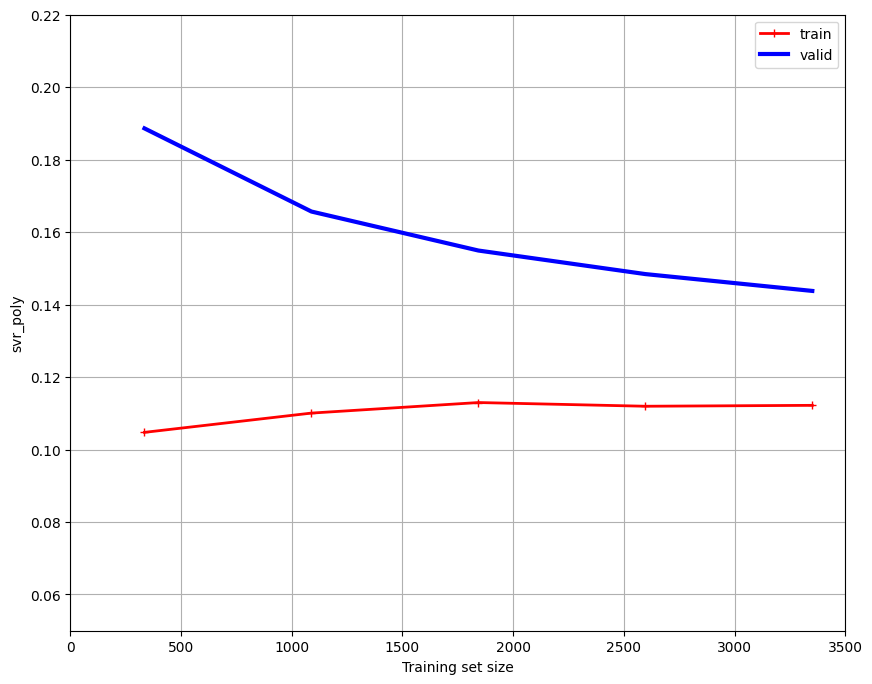

svr_poly: 0.14365870277778053


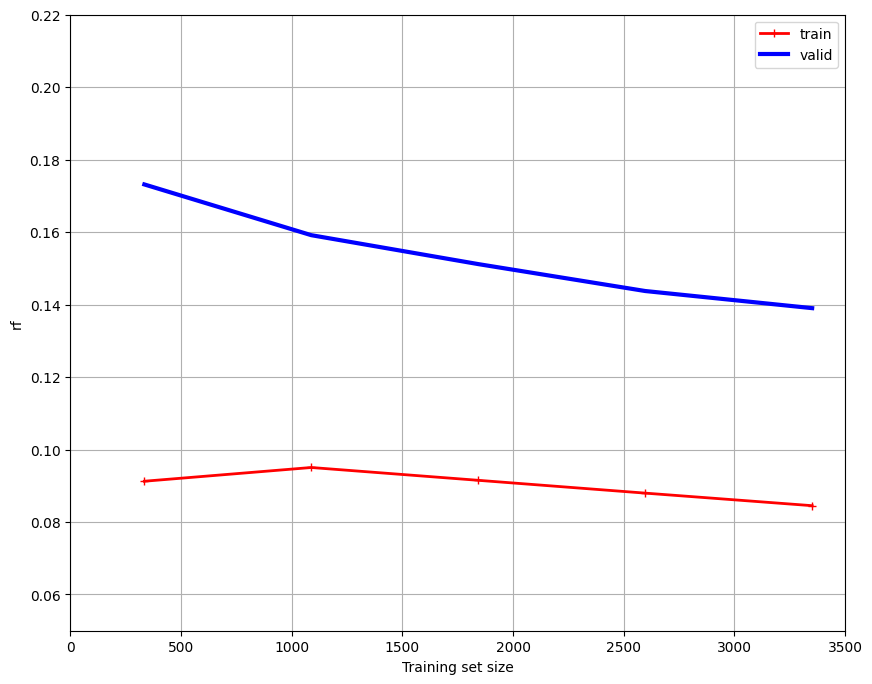

rf: 0.13838391159377217


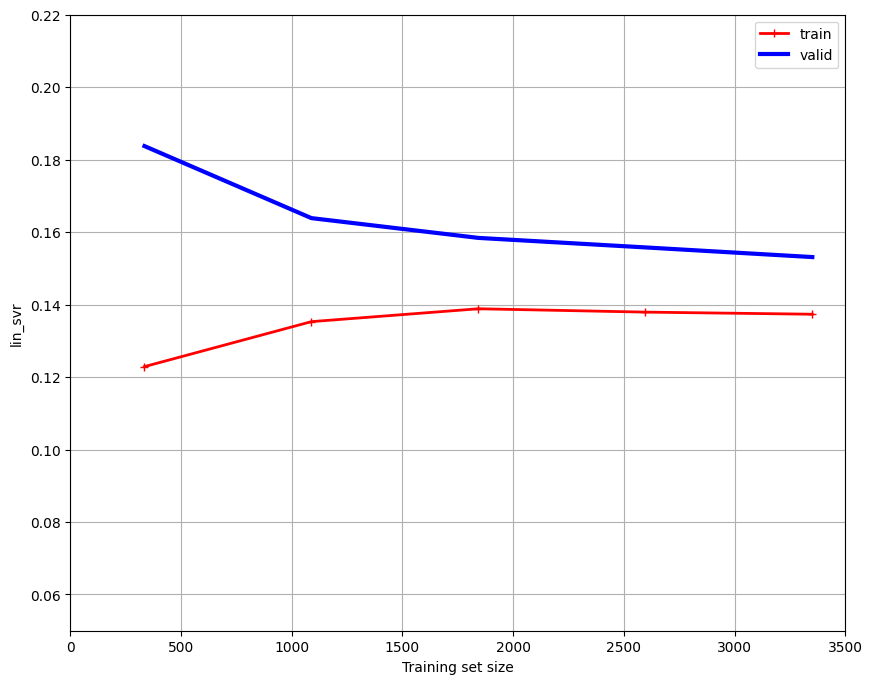

lin_svr: 0.1532279145588355


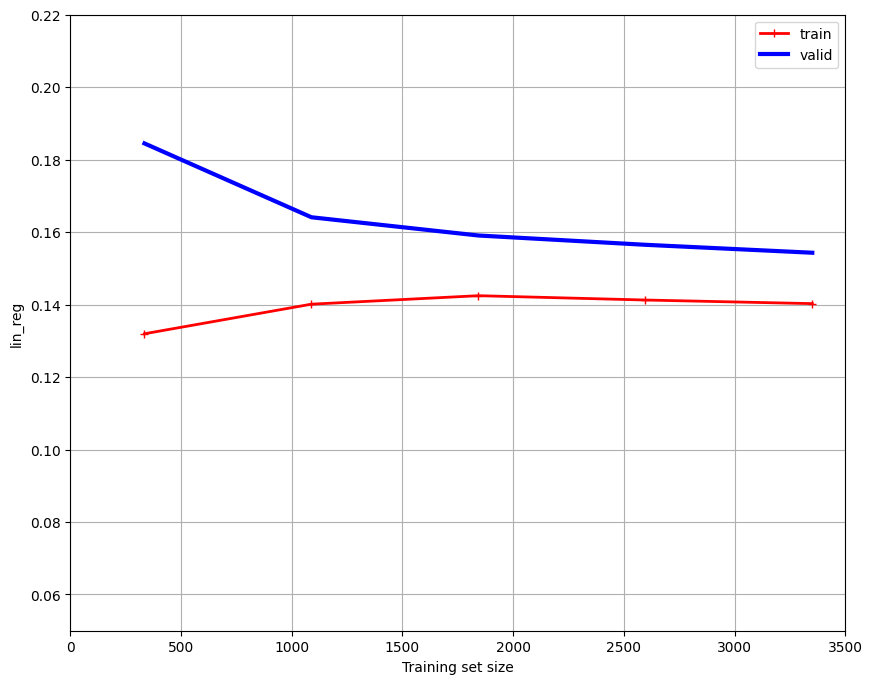

lin_reg: 0.15433407812333372


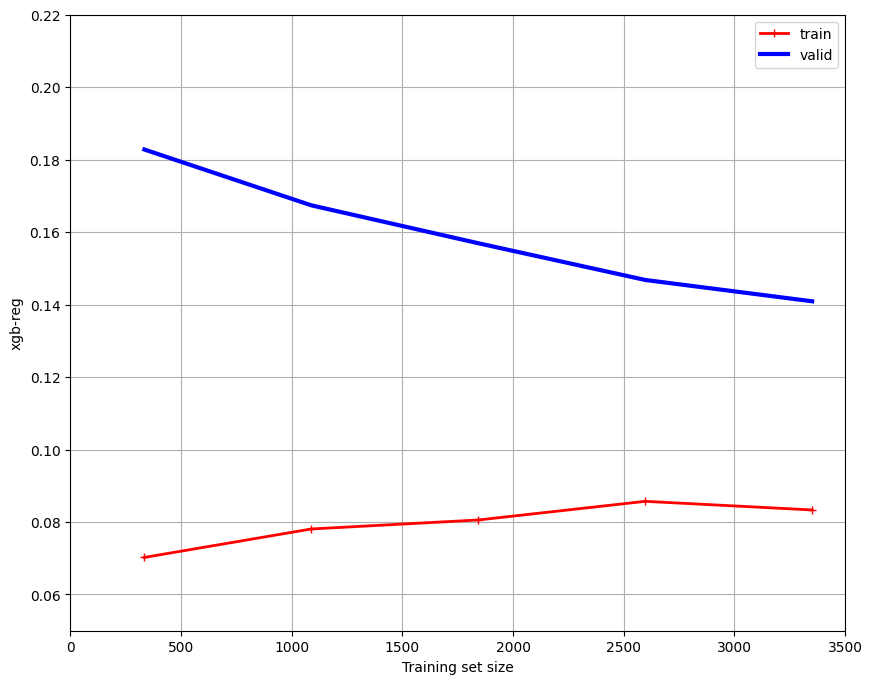

xgb-reg: 0.1398337889322431


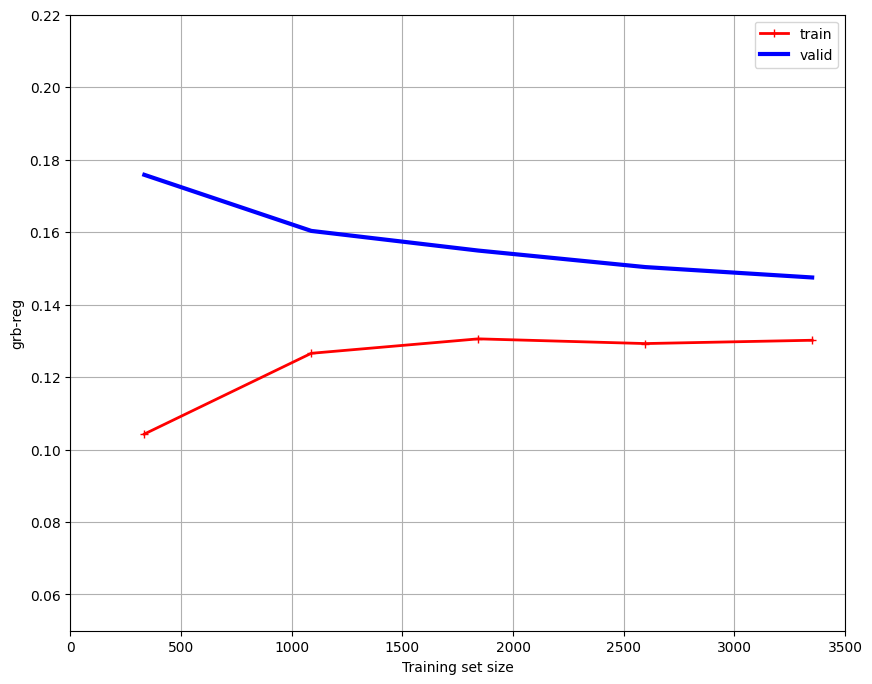

grb-reg: 0.1476057355850165


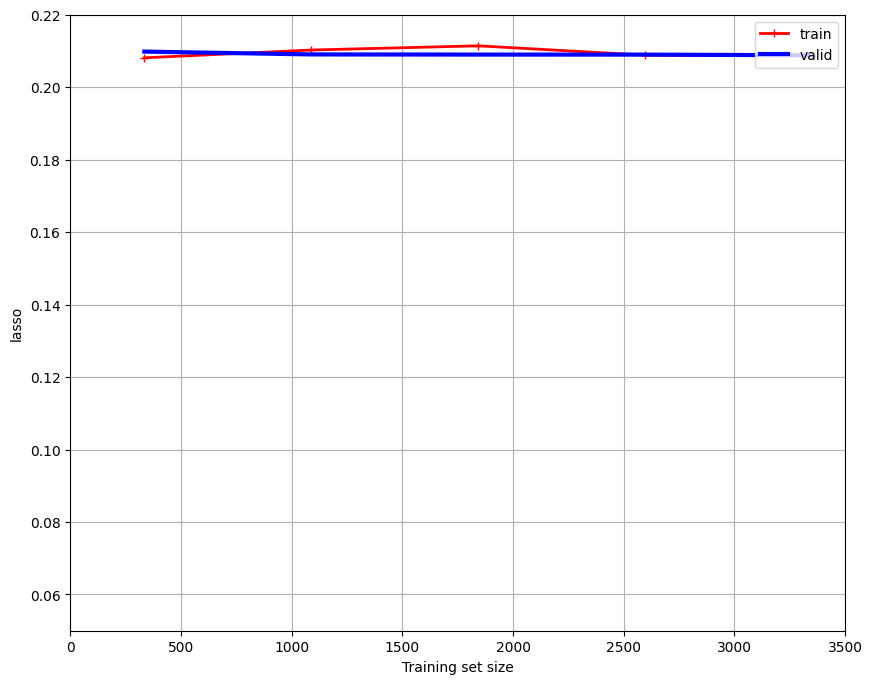

lasso: 0.20881047501648364


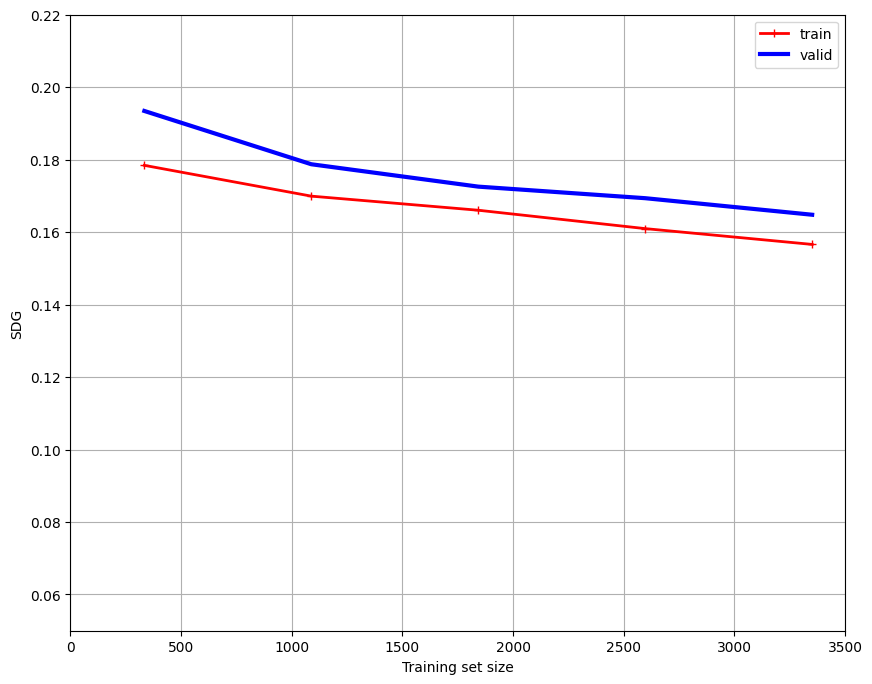

SDG: 0.16495355489431698


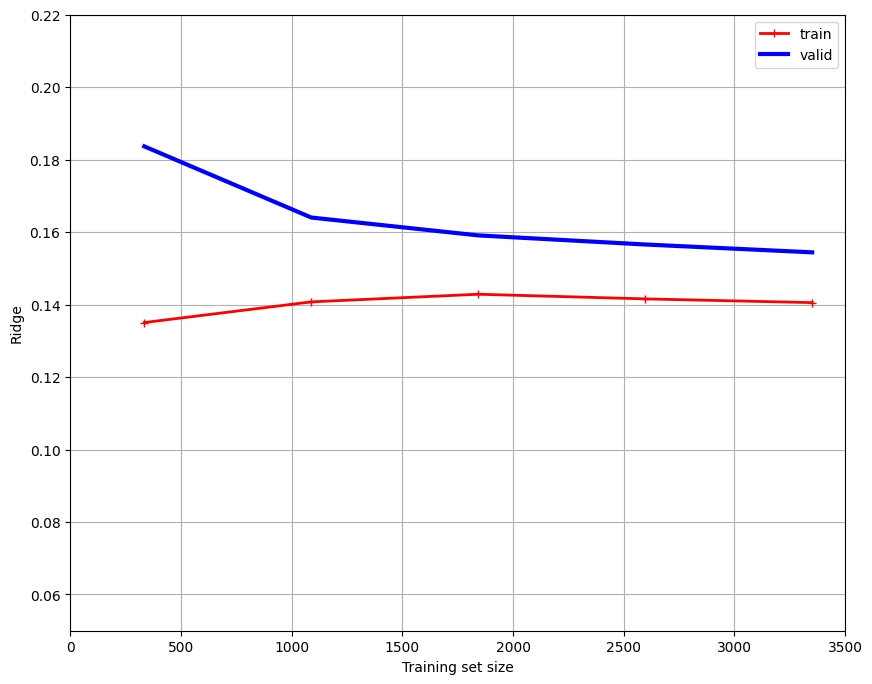

Ridge: 0.15445687809866188


In [162]:
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import LinearSVR
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge, SGDRegressor
from xgboost import XGBRegressor
regressors =[
              ('svr_poly', SVR()),
              ('rf', RandomForestRegressor(random_state=42)),
              ('lin_svr', LinearSVR(random_state=42)),
              ('lin_reg', LinearRegression()),
              ('xgb-reg', XGBRegressor(random_state=42)),
              ('grb-reg', GradientBoostingRegressor(random_state=42)),
              ('lasso', Lasso(random_state=42)),
              ('SDG', SGDRegressor(random_state=42)),
              ('Ridge', Ridge(random_state=42))]

for name, model in regressors:
  pipeline = Pipeline(steps=[('prep', preprocessing), (name, model)])
  mae = np.mean(cross_val_score(pipeline,X_train, y_train, cv=5, scoring='neg_mean_absolute_error'))
  train_sizes, train_scores, valid_scores = learning_curve(pipeline,X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
  train_errors = -train_scores.mean(axis=1)
  valid_errors = -valid_scores.mean(axis=1)
  plt.figure(figsize=(10, 8))  
  plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
  plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
  plt.xlabel("Training set size")
  plt.ylabel(name)
  plt.grid()
  plt.legend(loc="upper right")
  plt.axis([0,3500, 0.05, 0.22])
  plt.show()
  print(f"{name}: {-mae}")



Ik maak de keuze om verder te gaan met XGboost en Randomforest. Ik merk wel op dat ze allebei aan het overfitting waren. 

Een alternatieve keuze die ik had kunnen maken was om verder te gaan met SGD, omdat die het minste overfitting had.

Aangezien dat de cross_val_score van XGBoost en Randomforest beter waren dan de mean absolute score van SGD zonder cross validation, blijf ik bij XGBoost en RandomForest

Om de beste paramemters te zoeken was ik eerst heel ruim begonnen, en dan specifiek geëindigd. 

In [ ]:
#Beste parameters zoeken van XGB
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
xgb_model = XGBRegressor(random_state=42, objective='reg:absoluteerror')
pipeline = make_pipeline(preprocessing, xgb_model)


param_grid = [
  {'xgbregressor__learning_rate': [0.05, 0.01],
   'xgbregressor__n_estimators': np.arange(580,591,1),
   'xgbregressor__max_depth': [0, 5,10, 15],
   'xgbregressor__colsample_bytree': [0, 0.25, 0.5]}

]

#https://apmonitor.com/pds/index.php/Main/XGBoostClassifier

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='neg_mean_absolute_error', return_train_score=True, verbose=4, n_jobs=-1)

grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(-grid_search.best_score_)


In [170]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
forest_reg = RandomForestRegressor(random_state=42)
pipeline = make_pipeline(preprocessing, forest_reg)


param_grid = [
  {'randomforestregressor__bootstrap': [False, True],
   'randomforestregressor__n_estimators': np.arange(545,566,1),
   'randomforestregressor__max_depth': np.arange(25,36,1),
   'randomforestregressor__max_features': [10], #MaxFeatures, min samples split en leaf zijn in een eerdere itteratie al bepaald
   'randomforestregressor__min_samples_split': [5],
   'randomforestregressor__min_samples_leaf': [1]}
]

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='neg_mean_absolute_error',  return_train_score=True, verbose=4, n_jobs=-1)

grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(-grid_search.best_score_)

Fitting 5 folds for each of 462 candidates, totalling 2310 fits
{'randomforestregressor__bootstrap': False, 'randomforestregressor__max_depth': np.int64(29), 'randomforestregressor__max_features': 10, 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__min_samples_split': 5, 'randomforestregressor__n_estimators': np.int64(550)}
0.13286258862285724


Ik lijst de regressors die ik ga gebruiken voor VotingRegressor en StackingRegressor

In [20]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge, SGDRegressor
from xgboost import XGBRegressor
regressors =[
              ('rf', RandomForestRegressor(random_state=42, n_estimators=550, max_depth=29, min_samples_leaf=1, max_features=10, min_samples_split=5)),
              ('xgb-reg', XGBRegressor(random_state=42, learning_rate=0.05, colsample_bytree=0.5, max_depth=10, n_estimators=588)),
              ]


In [21]:
from sklearn.ensemble import VotingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

voting = VotingRegressor(estimators=regressors)

pipeline_voting = Pipeline(steps=[('prep', preprocessing), ('voting', voting)])
pipeline_voting.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('voting', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('high', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform

In [130]:

from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_absolute_error

ada_clf = AdaBoostRegressor(estimator=XGBRegressor(random_state=42, learning_rate=0.05, colsample_bytree=0.5, max_depth=10, n_estimators=588))

pipeline_ada_clf = Pipeline(steps=[('prep', preprocessing), ('ada', ada_clf)])
pipeline_ada_clf.fit(X_train, y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('ada', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('high', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers

In [22]:
from sklearn.ensemble import StackingRegressor

stacking_clf = StackingRegressor(estimators=regressors, final_estimator=XGBRegressor(random_state=42, learning_rate=0.05, colsample_bytree=0.5, max_depth=10, n_estimators=588), cv=5)

pipeline_stacking_clf = Pipeline(steps=[('prep', preprocessing), ('stacking', stacking_clf)])
pipeline_stacking_clf.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('stacking', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('high', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfo

Ik maak mijn regressors ook nog een keer apart aan. Dit geeft een goed referentiepunt om te zien of dat boosting, voting en stacking iets opbrengt

In [23]:
#Mijn 2 beste modellen als solo modellen exporteren om te vergelijken

rf = RandomForestRegressor(random_state=42, n_estimators=550, max_depth=29, min_samples_leaf=1, max_features=10, min_samples_split=5)
pipeline_rf = Pipeline(steps=[('prep', preprocessing), ('rf', rf)])
pipeline_rf.fit(X_train, y_train)
xgb = XGBRegressor(random_state=42, learning_rate=0.05, colsample_bytree=0.5, max_depth=10, n_estimators=588)
pipeline_xgb = Pipeline(steps=[('prep', preprocessing), ('xgb', xgb)])
pipeline_xgb.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('xgb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('high', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers

Voor elke model print ik:
- De mean absolute eror van de training data
- De root mean squared error van de training data
- De mean squared error van de training data
- De mean absolute eror van de test data
- De root mean squared error van de test data
- De mean squared error van de test data

Met dit kunnen we de volgende dingen te weten komen. 
- Als de model veel beter scoort op de trainings data, dan hebben we veel overfitting. 
- Als de model een goede MAE heeft, maar een slechtere MSE, dan zitten we met outliers in onze predictie.

In [175]:
models = [('stacking', pipeline_stacking_clf), ('ada',pipeline_ada_clf) , ('voting', pipeline_voting) , ('xgb', pipeline_xgb), ('rf', pipeline_rf)]

for name, model in models:

  mae= np.mean(cross_val_score(model,X_train, y_train, cv=5, scoring='neg_mean_absolute_error'))
  rmse= np.mean(cross_val_score(model,X_train, y_train, cv=5, scoring='neg_root_mean_squared_error'))
  r2= np.mean(cross_val_score(model,X_train, y_train, cv=5, scoring='r2'))

  mae_test = mean_absolute_error(y_test, model.predict(X_test))
  rmse_test = root_mean_squared_error(y_test, model.predict(X_test))
  r2_test = model.score(X_test, y_test)

  print(f"Voor model {name}:")
  print(f"mae:  {-mae}")
  print(f"rmse:  {-rmse}")
  print(f"r2:  {r2}")

  print()
  print(f"mae test:  {mae_test}")
  print(f"rmse test:  {rmse_test}")
  print(f"r2 test:  {r2_test}")

  print()



Voor model stacking:
mae:  0.14629144109585318
rmse:  0.19096574650417375
r2:  0.4273804454294816

mae test:  0.13511543424152972
rmse test:  0.18222299908894768
r2 test:  0.4402165885468631

Voor model ada:
mae:  0.13867571435532533
rmse:  0.1790863224067411
r2:  0.4967391923761125

mae test:  0.13348308925252292
rmse test:  0.17555411124468265
r2 test:  0.4804400656150226

Voor model voting:
mae:  0.13268983765470393
rmse:  0.17539495202614913
r2:  0.5169039642493953

mae test:  0.12728009732938605
rmse test:  0.17236615516504825
r2 test:  0.4991385196438597

Voor model xgb:
mae:  0.13324431240555407
rmse:  0.17837343274500128
r2:  0.5003896182276965

mae test:  0.13019553141353538
rmse test:  0.17695209110785143
r2 test:  0.47213235571524914

Voor model rf:
mae:  0.13555811901110715
rmse:  0.17726339674344488
r2:  0.5065109117591351

mae test:  0.12880066820339856
rmse test:  0.17257768587134534
r2 test:  0.4979084336917552



Aangezien dat de gevraagde metric MAE is, kiezen we onze model op basis daarvan. Voting regressor dus onze model van keuze.

Let op: RMSE zit .04 hoger. Dat is niet veel, maar dat betekent wel dat we met outliers zitten als het om de predictie gaat.

We bekijken nu de feature importance van Voting Regressor. Van Voting Regressor zelf kan je het niet rechtstreeks halen, maar aangezien dat het de combinatie is van 2 modellen, ga ik de gemiddelde nemen van hun features

In [176]:
models = [('rf', pipeline_rf), ('xgb', pipeline_xgb)]
sorted_features_rf = sorted(zip(pipeline_rf.named_steps['prep'].get_feature_names_out() , pipeline_rf.named_steps['rf'].feature_importances_), key=lambda x: x[1], reverse=True)
sorted_features_xgb = sorted(zip(pipeline_xgb.named_steps['prep'].get_feature_names_out() , pipeline_xgb.named_steps['xgb'].feature_importances_), key=lambda x: x[1], reverse=True)
sorted_features_mean = sorted(zip(pipeline_rf.named_steps['prep'].get_feature_names_out() , (pipeline_rf.named_steps['rf'].feature_importances_ + pipeline_xgb.named_steps['xgb'].feature_importances_)/2), key=lambda x: x[1], reverse=True)

print(sorted_features_rf)
print(sorted_features_xgb)
print(sorted_features_mean)



[('high__SubgroupCode', np.float64(0.2534275796348364)), ('high__ProgramName', np.float64(0.1447930691187362)), ('num__Ruimte', np.float64(0.057356624099946185)), ('num__DayOfYear_cos', np.float64(0.04583405358644134)), ('num__DayOfYear_sin', np.float64(0.04354721806315166)), ('num__Capacity', np.float64(0.04220883664859283)), ('num__Area', np.float64(0.04113865611142194)), ('num__ClassCredits', np.float64(0.036370292380130946)), ('num__temp_avg', np.float64(0.029768026745574057)), ('num__sun_int_avg', np.float64(0.029440584166447067)), ('num__sun_duration', np.float64(0.024650008108260596)), ('num__ClassTime', np.float64(0.02116586373881797)), ('num__precip_quantity', np.float64(0.020668309415646218)), ('num__UntillHour_sin', np.float64(0.018852587651038297)), ('num__UntillHour_cos', np.float64(0.018354366362050515)), ('num__FromHour_sin', np.float64(0.01783893481610121)), ('num__Weekday_sin', np.float64(0.01747381851060891)), ('num__RoomFloor', np.float64(0.016944931771405092)), ('nu

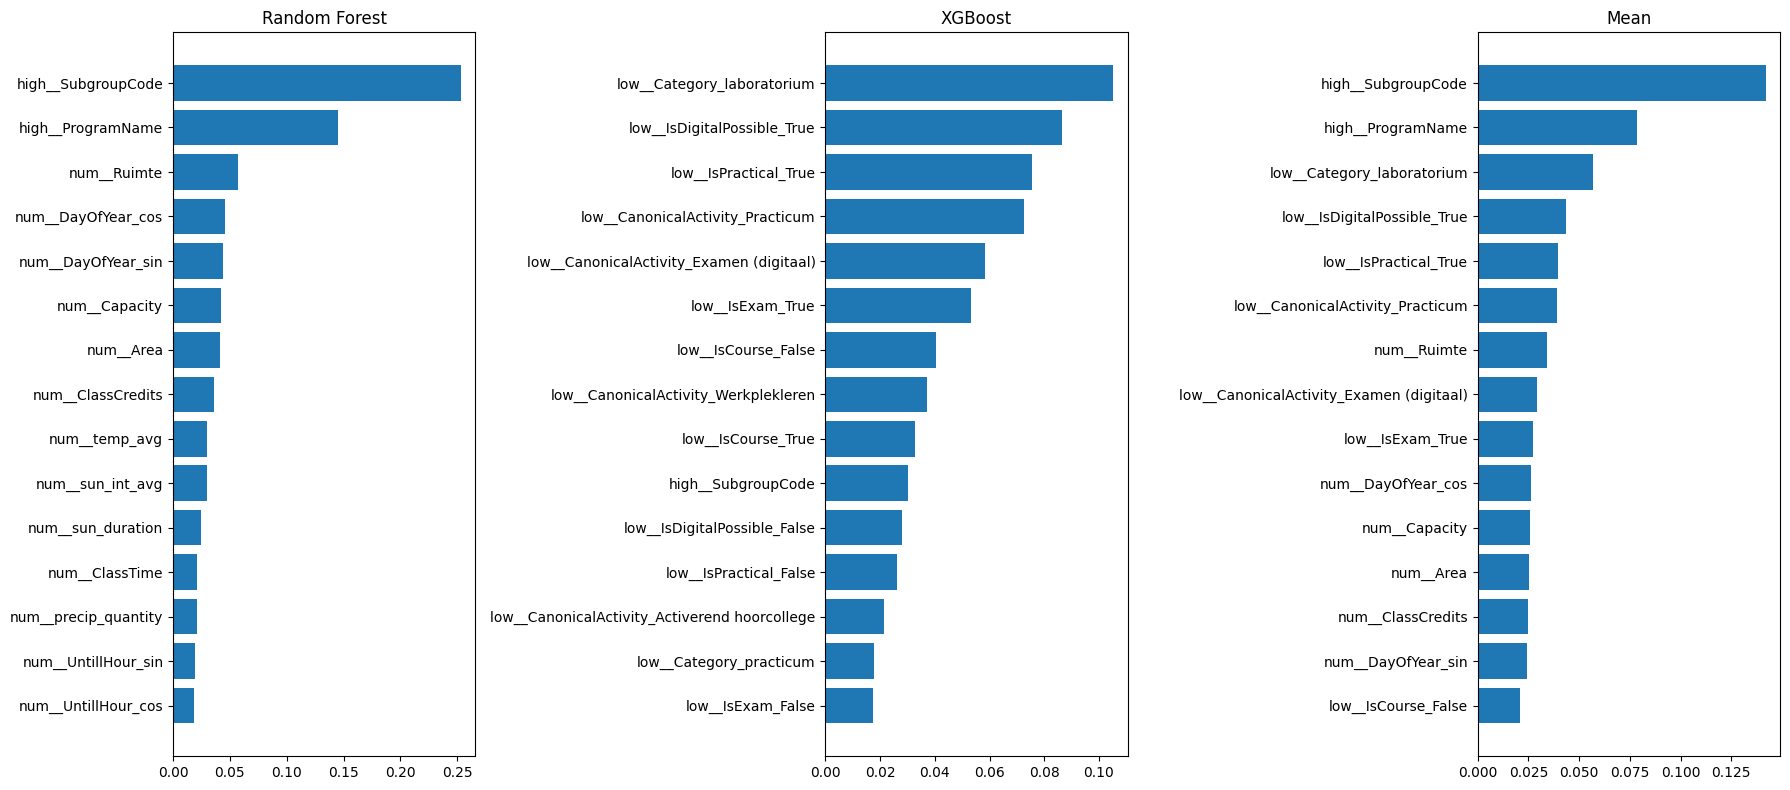

In [177]:
#49 features in totaal, we bekijken top en bodem 15
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

plots = [
    ("Random Forest", sorted_features_rf),
    ("XGBoost", sorted_features_xgb),
    ("Mean", sorted_features_mean)
]

for ax, (title, data) in zip(axes, plots):
    features, importances = zip(*data[:15])
    ax.barh(features, importances)
    ax.invert_yaxis()
    ax.set_title(title)

plt.tight_layout()
plt.show()

#Weinig overlap: Random forest geeft voorkeur aan SubgroupCode en ProgramName (De verschillende klassen) en de numerical_cols
#XGBoost geeft de voorkeur aan categorien met een lage cardinality

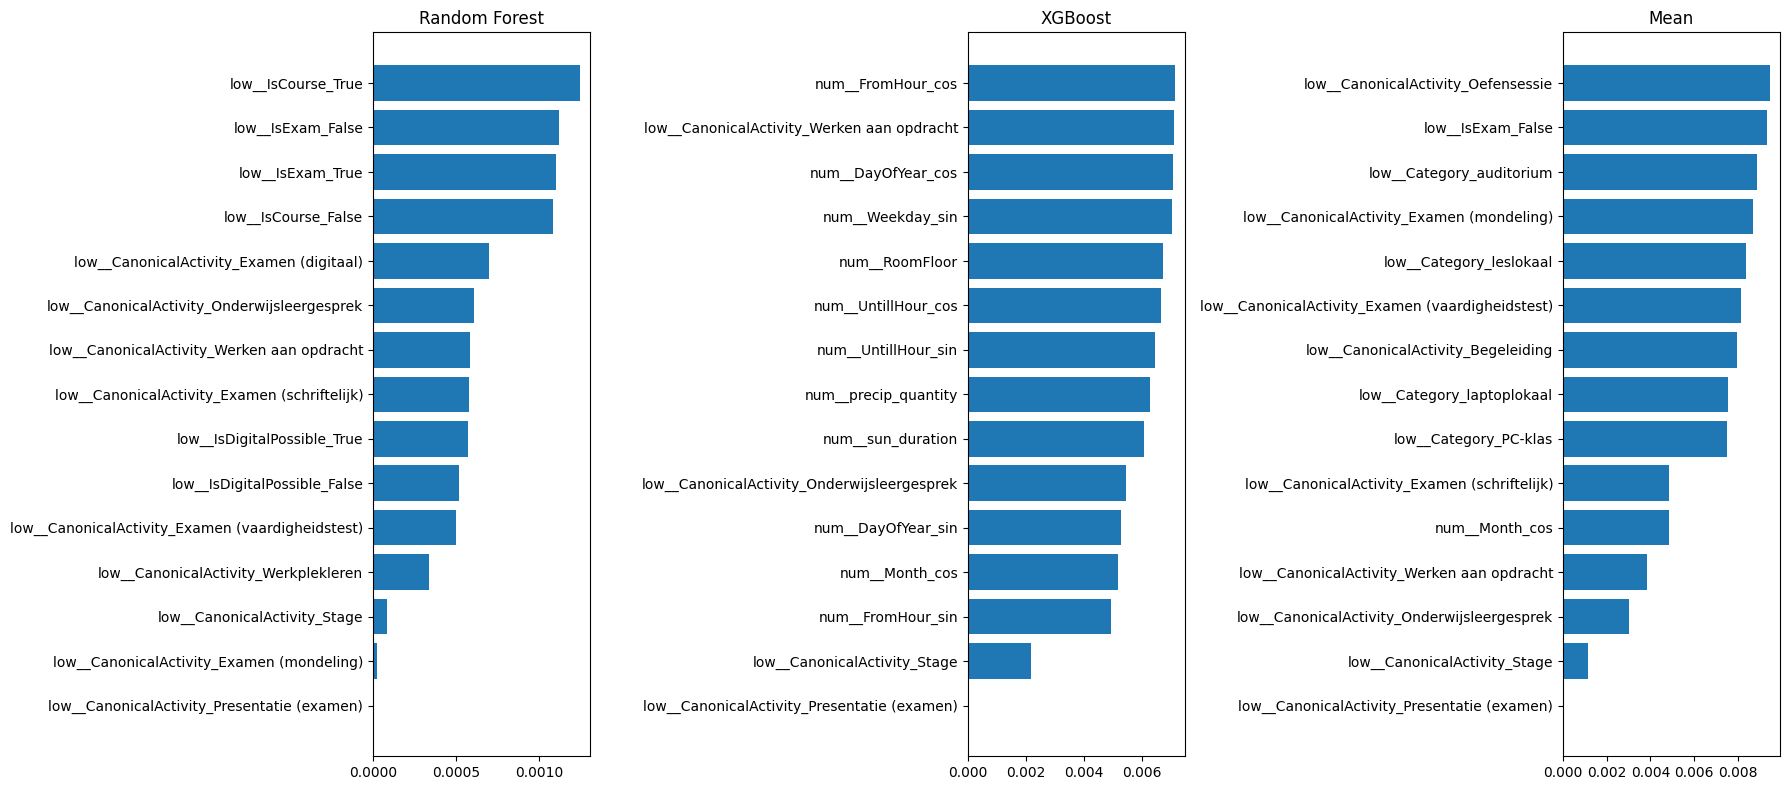

In [178]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

plots = [
    ("Random Forest", sorted_features_rf),
    ("XGBoost", sorted_features_xgb),
    ("Mean", sorted_features_mean)
]

for ax, (title, data) in zip(axes, plots):
    features, importances = zip(*data[-15:])
    ax.barh(features, importances)
    ax.invert_yaxis()
    ax.set_title(title)

plt.tight_layout()
plt.show()

#Random Forest heeft een afkeur aan categoriën met een lage cardinaliteit
#XGBoost heeft een afkeur aan de numerical_categories
#Bij allebei staat canonicalActivity_presentatie (examen) aangeduid al laatste, en XGBoost heeft een afkeur voor een paar canonicalactivities
#Dit is gemakkelijk te verklaren eens je kijkt met X_train['CanonicalActivity'].value_counts()
#We hebben hiervan gewoon niet genoeg data om een beslissing te maken.
#Werken aan opdracht             9
#Examen (digitaal)               8
#Examen (mondeling)              3
#Presentatie (examen)            1


In [25]:
import joblib
joblib.dump(pipeline_voting, 'voting_regressor.pkl')
joblib.dump(pipeline_xgb, 'xgb_regressor.pkl')
joblib.dump(pipeline_rf, 'random_forest.pkl')


['random_forest.pkl']